## 1. Setup

In [1]:
# !cp /kaggle/input/datasets/rahulsingh147/models-tokenizer/tokenizerv3.pkl .
# !mkdir ./base-models
# !cp /kaggle/input/datasets/rahulsingh147/models-tokenizer/gqa-rope.pt ./base-models/
# !cp /kaggle/input/datasets/rahulsingh147/models-tokenizer/mla-sin.pt ./base-models/
# !cp /kaggle/input/datasets/rahulsingh147/models-tokenizer/gqa-rope-swiglu-moe.pt ./base-models/
# !cp /kaggle/input/datasets/rahulsingh147/models-tokenizer/swiglu-moe-rope-conv.pt ./base-models/

In [2]:
# Imports
import os, gc, copy, time, math, random, re, json, pickle, zipfile, shutil
from dataclasses import dataclass, replace
from collections import defaultdict, Counter

import numpy as np, pandas as pd
from tqdm import tqdm

import torch, torch.nn as nn, torch.nn.functional as F
from torch.amp import GradScaler, autocast
from torch.utils.checkpoint import checkpoint

from huggingface_hub import hf_hub_download, login
from kaggle_secrets import UserSecretsClient

# Hugging Face login Secret
login(token=UserSecretsClient().get_secret("HF"))
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"

# Data location
HF_DATASET_REPO = "Exploration-Lab/CS-781-Capstone"
PHASE2_DIR      = "Phase_2_LNER"
IGN             = -100        # ignored position in the token-label sequence (<s>, whitespace-only tokens, padding)

# "full"     -> complete data and epochs (final runs, submissions)
# "ablation" -> fixed, seeded slice of the data + capped epochs: enough to compare methods quickly
# "smoke"    -> a handful of documents, 1 epoch: verifies the whole pipeline in minutes
RUN_MODE = "full"
RUN_SETTINGS = {"full":     dict(train_frac=1.0, val_frac=1.0, test_frac=1.0, max_epochs=None, write_test=True),
                "ablation": dict(train_frac=0.3, val_frac=0.5, test_frac=1.0, max_epochs=3,    write_test=False),
                "smoke":    dict(n_train=8,      n_val=4,      n_test=4,      max_epochs=1,    write_test=True)}
RS  = RUN_SETTINGS[RUN_MODE]
OUT = {"full": "./cs781_phase2", "ablation": "./cs781_phase2_ablation", "smoke": "./cs781_phase2_smoke"}[RUN_MODE]
os.makedirs(OUT, exist_ok=True)

# Phase 1 model hyper-parameters
VOCAB_SIZE       = 20_000
TRAIN_BLOCK_SIZE = 2048
N_EMBD           = 768
N_LAYER          = 12
N_HEAD           = 12
N_KV_HEAD        = 4
KV_LATENT_DIM    = N_EMBD // 4

PHASE1_CONFIGS = {"gqa-rope":             {"n_layers": 8,  "d_ff": 4 * 768, "attention_type": "gqa", "pos_emb_type": "rope",       "use_moe": False, "use_conv": False},
                  "mla-sin":              {"n_layers": 12, "d_ff": 4 * 768, "attention_type": "mla", "pos_emb_type": "sinusoidal", "use_moe": False, "use_conv": False},
                  "gqa-rope-swiglu-moe":  {"n_layers": 12, "d_ff": 1408,    "attention_type": "gqa", "pos_emb_type": "rope",       "use_moe": True,  "use_conv": False},
                  "swiglu-moe-rope-conv": {"n_layers": 12, "d_ff": 1408,    "attention_type": "gqa", "pos_emb_type": "rope",       "use_moe": True,  "use_conv": True, "local_kernel_size": 25},
                  }
MAIN_MODEL = "gqa-rope-swiglu-moe"      # model used for the technique / ablation experiments

# ── Long-document representation ──
WINDOW_LEN = 512             # tokens per window (a <s> token is added in front); consecutive windows overlap by half

# ── Training ──
BATCH_SIZE        = 8        # windows per step
WARMUP_FRAC       = 0.1
WEIGHT_DECAY      = 0.01
HEAD_DROPOUT      = 0.1
CW_CAP            = 3.0      # upper bound of the inverse-frequency class weights
FOCAL_GAMMA       = 2.0
ADALORA_ORTH_COEF = 0.01
GRAD_CLIP         = 1.0
USE_AMP_TRAIN     = False    # fp32 training (as in the runs that produced the existing results)
USE_AMP_PREDICT   = True     # fp16 autocast at inference

SEED = 42
def set_seed(seed):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed); torch.cuda.manual_seed_all(seed)
set_seed(SEED)
torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = False

## 2. Tokenizer

In [3]:
class ByteLevelBPE:
    def __init__(self, vocab_size=5000):
        self.vocab_size = vocab_size
        self.reserved = ["<pad>", "<unk>", "<s>", "</s>"]
        self.itos = list(self.reserved); self.stoi = {}; self.merges = []; self.ranks = {}; self.merged_map = {}; self._cache = {}
        # Regex pattern matching words, numbers, individual punctuation, and whitespace sequences
        self.pattern = r"""'s|'t|'re|'ve|'m|'ll|'d| ?[^\s\W\d_]+| ?\d+| ?[^\s\w]+|\s+(?!\S)|\s+"""
        self.pat = re.compile(self.pattern, re.UNICODE)

    def fit(self, texts, max_unique_words=200000):
        """Train a byte-level BPE tokenizer using inverted indexing for fast merging."""
        raw_counts = Counter()
        iterator = [texts] if isinstance(texts, str) else texts

        # Preserve whitespace tokens when populating initial raw_counts
        for text in tqdm(iterator, desc="Building word vocabulary"):
            for chunk in re.findall(self.pattern, str(text), flags=re.UNICODE):
                raw_counts[chunk] += 1

        if max_unique_words and len(raw_counts) > max_unique_words:
            most_common = raw_counts.most_common(max_unique_words)
            raw_counts = dict(most_common)

        word_freqs = {}; pair_counts = defaultdict(int); pair_to_words = defaultdict(set)
        for word, count in raw_counts.items():
            encoded = word.encode("utf-8")
            byte_word = tuple(encoded[i:i+1] for i in range(len(encoded)))
            word_freqs[byte_word] = count

            for i in range(len(byte_word) - 1):
                pair = (byte_word[i], byte_word[i + 1])
                pair_counts[pair] += count
                pair_to_words[pair].add(byte_word)

        base_bytes = sorted({token for word in word_freqs for token in word})
        self.itos = list(self.reserved) + base_bytes; self.merges = []
        target_merges = self.vocab_size - len(self.itos)

        with tqdm(total=target_merges, desc="Training BPE Merges") as pbar:
            while len(self.itos) < self.vocab_size:
                if not pair_counts:
                    break
                best_pair = max(pair_counts, key=lambda p: (pair_counts[p], p[0], p[1]))
                if pair_counts[best_pair] <= 0:
                    break
                merged_token = best_pair[0] + best_pair[1]
                self.merges.append((best_pair, merged_token))
                self.itos.append(merged_token)
                
                words_to_update = list(pair_to_words[best_pair])
                del pair_counts[best_pair]
                del pair_to_words[best_pair]

                p0, p1 = best_pair
                for word in words_to_update:
                    count = word_freqs.get(word, 0)
                    if count == 0:
                        continue

                    new_word = []; i = 0; n = len(word)
                    while i < n:
                        if i + 1 < n and word[i] == p0 and word[i + 1] == p1:
                            new_word.append(merged_token)
                            i += 2
                        else:
                            new_word.append(word[i])
                            i += 1
                    new_word = tuple(new_word)
                    
                    for j in range(len(word) - 1):
                        old_p = (word[j], word[j + 1])
                        if old_p in pair_counts:
                            pair_counts[old_p] -= count
                            if pair_counts[old_p] <= 0:
                                del pair_counts[old_p]

                    for j in range(len(new_word) - 1):
                        new_p = (new_word[j], new_word[j + 1])
                        pair_counts[new_p] += count
                        pair_to_words[new_p].add(new_word)

                    del word_freqs[word]
                    word_freqs[new_word] = count

                pbar.update(1)

        self.vocab_size = len(self.itos)
        self.stoi = {token: idx for idx, token in enumerate(self.itos)}
        self.ranks = {pair: rank for rank, (pair, _) in enumerate(self.merges)}
        self.merged_map = {pair: merged for pair, merged in self.merges}
        self._cache = {}
        return self

    def encode_word(self, word):
        """Encode single word using memoization and local pair updates."""
        if word in self._cache:
            return self._cache[word]

        encoded = word.encode("utf-8")
        tokens = [encoded[i:i+1] for i in range(len(encoded))]

        if len(tokens) <= 1:
            res = [self.stoi.get(token, self.stoi["<unk>"]) for token in tokens]
            self._cache[word] = res
            return res

        while len(tokens) > 1:
            min_rank = float("inf")
            min_pair = None

            for i in range(len(tokens) - 1):
                pair = (tokens[i], tokens[i + 1])
                rank = self.ranks.get(pair, float("inf"))
                if rank < min_rank:
                    min_rank = rank
                    min_pair = pair

            if min_pair is None or min_rank == float("inf"):
                break

            merged = self.merged_map[min_pair]
            new_tokens = []
            i = 0
            n = len(tokens)
            p0, p1 = min_pair

            while i < n:
                if i + 1 < n and tokens[i] == p0 and tokens[i + 1] == p1:
                    new_tokens.append(merged)
                    i += 2
                else:
                    new_tokens.append(tokens[i])
                    i += 1
            tokens = new_tokens

        res = [self.stoi.get(token, self.stoi["<unk>"]) for token in tokens]
        self._cache[word] = res
        return res

    def encode(self, text):
        """Encode a sentence while preserving original spaces and newlines."""
        ids = [self.stoi["<s>"]]
        pattern = r"""'s|'t|'re|'ve|'m|'ll|'d| ?[^\s\W\d_]+| ?\d+| ?[^\s\w]+|\s+(?!\S)|\s+"""
        for chunk in re.findall(pattern, str(text), flags=re.UNICODE):
            ids.extend(self.encode_word(chunk))
        ids.append(self.stoi["</s>"])
        return ids
    
    def decode(self, ids):
        """Decode BPE token IDs back into text seamlessly."""
        byte_list = []
        for idx in ids:
            tok = self.itos[idx] if 0 <= idx < len(self.itos) else "<unk>"
            if tok not in self.reserved and isinstance(tok, bytes):
                byte_list.append(tok)
        try:
            return b"".join(byte_list).decode("utf-8", errors="ignore")
        except Exception:
            return ""

    def get_vocab_size(self):
        return self.vocab_size

def train_tokenizer(train_text: str, vocab_size: int):
    """Train A-1 BPE tokenizer on `train_text` and return the trained tokenizer."""
    tokenizer = ByteLevelBPE(vocab_size)
    tokenizer.fit(train_text)
    return tokenizer
    
# Load Pretrained Tokenizer
with open("tokenizerv3.pkl", "rb") as f:
    tokenizer = pickle.load(f)
BOS, PAD, UNK, EOS = (tokenizer.stoi[t] for t in ("<s>", "<pad>", "<unk>", "</s>"))
assert len(tokenizer.itos) == VOCAB_SIZE
print("tokenizer vocab:", len(tokenizer.itos))

tokenizer vocab: 20000


## 3. Model Class Definitions

In [4]:
@dataclass
class LMConfig:
    vocab_size: int = VOCAB_SIZE
    d_model: int = N_EMBD
    n_layers: int = N_LAYER
    n_heads: int = N_HEAD
    n_kv_heads: int = N_KV_HEAD
    kv_latent_dim: int = KV_LATENT_DIM
    d_ff: int = 1408          # For SwiGLU (2/3) * 4 * d_model => 2/3 * 2048 = 1365 --> round to nearest upper multiple of 64 (1408)
    max_seq_len: int  = TRAIN_BLOCK_SIZE
    dropout: float = 0.0            # ~1 pass over the data -> no need for dropout
    pos_emb_type: str = "rope"      # "rope" or "sinusoidal"
    attention_scale: float = None
    norm_first: bool = True         # FIX: pre-LN (post-LN + lr 1e-3 + no warm-up is unstable)
    n_experts:  int   = 4
    top_k:      int   = 2
    aux_loss_coef: float = 0.01
    attention_type: str = "gqa"
    use_moe: bool = False, 
    use_conv: bool = False
    local_kernel_size: int = 25
    
# Rotary Positional Embeddings
def build_rope_cache(max_seq_len: int, d_head: int, base: float = 10000.0):
    """ Returns (cos, sin) : the split-half rotate_half convention: channel i is paired with channel i+d_head/2. """
    inv = 1.0 / (base ** (torch.arange(0, d_head, 2).float() / d_head))
    ang = torch.cat([torch.outer(torch.arange(max_seq_len).float(), inv)] * 2, -1)
    return ang.cos(), ang.sin()
def rotate_half(x: torch.Tensor) -> torch.Tensor:
    """Split the last dim in half and return (-x2, x1) concatenated -- the 90-degree rotation step used by the "rotate_half" formulation of RoPE."""
    x1, x2 = x[ ..., : x.shape[-1] // 2], x[..., x.shape[-1] // 2 : ]
    return torch.cat((-x2, x1), dim = -1)
def apply_rope(x: torch.Tensor, cos: torch.Tensor, sin: torch.Tensor) -> torch.Tensor:
    """ x: (B, n_heads, T, d_head) -- a query or key tensor. cos, sin: (T, d_head), sliced from build_rope_cache's output for the current T. Returns the rotated tensor, same shape as x. Formula: x_rotated = x * cos + rotate_half(x) * sin """
    cos, sin = (cos[None, None], sin[None, None]) if cos.dim() == 2 else (cos[:, None], sin[:, None])
    return x.float() * cos + rotate_half(x.float()) * sin

def sinusoidal_positional_encoding(max_len: int, d_model: int) -> torch.Tensor:
    pos = torch.arange(max_len, dtype=torch.float32).unsqueeze(1)
    i = torch.arange(0, d_model, 2, dtype=torch.float32)
    angle = pos / (10000 ** (i / d_model))
    return torch.stack([torch.sin(angle), torch.cos(angle)], dim=-1).reshape(max_len, d_model)

class CausalSelfAttention(nn.Module):
    def __init__(self, d_model, n_heads, n_kv_heads, max_seq_len, dropout=0.0, use_rope=True, attention_scale=None):
        super().__init__()
        assert d_model % n_heads == 0 and n_heads % n_kv_heads == 0
        self.n_heads, self.n_kv_heads = n_heads, n_kv_heads
        self.n_rep, self.d_head = n_heads // n_kv_heads, d_model // n_heads
        self.use_rope = use_rope
        self.attention_scale = (1.0 / math.sqrt(self.d_head)) if attention_scale is None else float(attention_scale)

        self.q_proj = nn.Linear(d_model, n_heads * self.d_head, bias=False)
        self.k_proj = nn.Linear(d_model, n_kv_heads * self.d_head, bias=False)
        self.v_proj = nn.Linear(d_model, n_kv_heads * self.d_head, bias=False)
        self.out_proj = nn.Linear(n_heads * self.d_head, d_model, bias=False)
        self.attn_dropout = nn.Dropout(dropout)
        self.resid_dropout = nn.Dropout(dropout)

        if use_rope:
            cos, sin = build_rope_cache(max_seq_len, self.d_head)
            self.register_buffer("rope_cos", cos, persistent=False)
            self.register_buffer("rope_sin", sin, persistent=False)

    def forward(self, x, position_ids=None, attn_mask=None, kv_cache=None, use_cache=False):
        B, T, C = x.shape
        q = self.q_proj(x).view(B, T, self.n_heads, self.d_head).transpose(1, 2)
        k = self.k_proj(x).view(B, T, self.n_kv_heads, self.d_head).transpose(1, 2)
        v = self.v_proj(x).view(B, T, self.n_kv_heads, self.d_head).transpose(1, 2)

        if self.use_rope:
            q = apply_rope(q, self.rope_cos[position_ids], self.rope_sin[position_ids])
            k = apply_rope(k, self.rope_cos[position_ids], self.rope_sin[position_ids])
             
        # Append to KV cache if provided
        if kv_cache is not None:
            past_k, past_v = kv_cache
            k = torch.cat([past_k, k], dim=-2)
            v = torch.cat([past_v, v], dim=-2)
        new_kv_cache = (k, v) if use_cache else None

        if self.n_rep > 1:
            k = k.repeat_interleave(self.n_rep, dim=1)
            v = v.repeat_interleave(self.n_rep, dim=1)

        # Only set is_causal=True if processing multiple prompt tokens at once (T > 1)
        is_causal = (attn_mask is None) and (kv_cache is None) and (T > 1)
        context = F.scaled_dot_product_attention(q, k, v, attn_mask=attn_mask, dropout_p=self.attn_dropout.p if self.training else 0.0,  is_causal=is_causal, scale=self.attention_scale)
        out = self.resid_dropout(self.out_proj(context.transpose(1, 2).reshape(B, T, C)))
        
        return (out, new_kv_cache) if use_cache else out

class MultiHeadLatentAttention(nn.Module):
    """Joint KV Compression Multi-Head Latent Attention module drop-in replacement for CausalSelfAttention."""

    def __init__(self, d_model, n_heads, kv_latent_dim, max_seq_len, dropout=0.0, attention_scale=None):
        super().__init__()
        assert (d_model % n_heads == 0 and 0 < kv_latent_dim < d_model), "d_model must be divisible by n_heads, and 0 < kv_latent_dim < d_model"

        self.n_heads, self.kv_latent_dim, self.d_head = n_heads, kv_latent_dim, d_model // n_heads
        self.attention_scale = ((1.0 / math.sqrt(self.d_head)) if attention_scale is None else float(attention_scale))

        # Projections
        self.q_proj = nn.Linear(d_model, d_model, bias=False)
        self.kv_down_proj = nn.Linear(d_model, kv_latent_dim, bias=False)
        self.k_up_proj = nn.Linear(kv_latent_dim, d_model, bias=False)
        self.v_up_proj = nn.Linear(kv_latent_dim, d_model, bias=False)
        self.out_proj = nn.Linear(d_model, d_model, bias=False)
        # Dropouts
        self.attn_dropout = nn.Dropout(dropout)
        self.resid_dropout = nn.Dropout(dropout)

    def forward(self, x, position_ids=None, attn_mask=None, kv_cache=None, use_cache=False):
        """Forward pass supporting sequence generation with KV cache and FlashAttention/SDPA."""
        B, T, C = x.shape
        q = (self.q_proj(x).reshape(B, T, self.n_heads, self.d_head).transpose(1, 2))  # (B, n_heads, T, d_head)
        c_kv = self.kv_down_proj(x)  # (B, T, kv_latent_dim)

        if kv_cache is not None:
            past_c_kv = (kv_cache[0] if isinstance(kv_cache, (tuple, list)) else kv_cache)
            c_kv = torch.cat([past_c_kv, c_kv], dim=1)  # Append along sequence dim T
        new_kv_cache = (c_kv,) if use_cache else None

        k = (self.k_up_proj(c_kv).view(B, -1, self.n_heads, self.d_head).transpose(1, 2))  # (B, n_heads, T_total, d_head)
        v = (self.v_up_proj(c_kv).view(B, -1, self.n_heads, self.d_head).transpose(1, 2))  # (B, n_heads, T_total, d_head)
        is_causal = (attn_mask is None) and (kv_cache is None) and (T > 1)
        
        context = F.scaled_dot_product_attention(q, k, v, attn_mask=attn_mask, dropout_p=self.attn_dropout.p if self.training else 0.0, is_causal=is_causal, scale=self.attention_scale)
        out = context.transpose(1, 2).contiguous().view(B, T, C)
        out = self.resid_dropout(self.out_proj(out))

        return (out, new_kv_cache) if use_cache else out

### Model Definitions
class FeedForward(nn.Module):
    def __init__(self, d_model: int, d_ff: int, dropout: float):
        super().__init__()
        self.net = nn.Sequential(nn.Linear(d_model, d_ff), nn.GELU(), nn.Linear(d_ff, d_model), nn.Dropout(dropout))
    def forward(self, x):
        return self.net(x)
        
class SwiGLUFeedForward(nn.Module):
    def __init__(self, d_model: int, d_ff: int, dropout: float):
        super().__init__()
        self.gate = nn.Linear(d_model, d_ff, bias=False); self.up   = nn.Linear(d_model, d_ff, bias=False); self.down = nn.Linear(d_ff, d_model, bias=False); self.drop = nn.Dropout(dropout)
    def forward(self, x):
        return self.drop(self.down(F.silu(self.gate(x)) * self.up(x)))

class TopKRouter(nn.Module):
    def __init__(self, d_model: int, n_experts: int, top_k: int):
        super().__init__()
        self.top_k  = top_k; self.linear = nn.Linear(d_model, n_experts, bias=False)
    def forward(self, x_flat):                           
        logits = self.linear(x_flat); topk_vals, topk_idx = torch.topk(logits, self.top_k, dim=-1)
        weights = F.softmax(topk_vals, dim=-1)            # (B*T, top_k)
        dispatch = torch.zeros_like(logits, dtype=weights.dtype)
        dispatch.scatter_(-1, topk_idx, weights)          # (B*T, n_experts)
        return dispatch, logits                           # logits kept for aux loss

class MoEFeedForward(nn.Module):
    def __init__(self, d_model, d_ff, n_experts, top_k, dropout, aux_coef=0.01):
        super().__init__()
        self.router   = TopKRouter(d_model, n_experts, top_k)
        self.experts  = nn.ModuleList([SwiGLUFeedForward(d_model, d_ff, dropout) for _ in range(n_experts)])
        self.aux_coef = aux_coef; self.aux_loss = torch.tensor(0.0)

    def forward(self, x):
        B, T, D = x.shape
        x_flat = x.reshape(B * T, D)
        dispatch, router_logits = self.router(x_flat)

        z = torch.logsumexp(router_logits, dim=-1)
        self.aux_loss = self.aux_coef * (z ** 2).mean()
        out = torch.zeros_like(x_flat)
        for e_idx, expert in enumerate(self.experts):
            w  = dispatch[:, e_idx];  mask = w > 0
            if not mask.any():
                continue
            out[mask] += w[mask].unsqueeze(-1) * expert(x_flat[mask])

        return out.reshape(B, T, D)

class Block(nn.Module):
    def __init__(self, cfg: LMConfig):
        super().__init__()
        self.norm_first = cfg.norm_first; self.ln1 = nn.LayerNorm(cfg.d_model); self.ln2 = nn.LayerNorm(cfg.d_model)
        if(cfg.attention_type == "mla"):
            self.attn = MultiHeadLatentAttention(cfg.d_model, cfg.n_heads, cfg.kv_latent_dim, cfg.max_seq_len, cfg.dropout, attention_scale=cfg.attention_scale)
        else:
            self.attn = CausalSelfAttention(cfg.d_model, cfg.n_heads, cfg.n_kv_heads, cfg.max_seq_len, cfg.dropout, use_rope=(cfg.pos_emb_type == "rope"), attention_scale=cfg.attention_scale)
        if(cfg.use_moe):
            self.ffn  = MoEFeedForward(cfg.d_model, cfg.d_ff, cfg.n_experts, cfg.top_k, cfg.dropout, cfg.aux_loss_coef)
        else:
            self.ffn = FeedForward(cfg.d_model, cfg.d_ff, cfg.dropout)
        
    def _attn(self, h, position_ids, attn_mask, kv_cache, use_cache):
        r = self.attn(h, position_ids=position_ids, attn_mask=attn_mask, kv_cache=kv_cache, use_cache=use_cache)
        return r if use_cache else (r, None)
        
    def forward(self, x, position_ids, attn_mask=None, kv_cache=None, use_cache=False):
        if self.norm_first:
            a, new_cache = self._attn(self.ln1(x), position_ids, attn_mask, kv_cache, use_cache)
            x = x + a
            x = x + self.ffn(self.ln2(x))
        else:
            a, new_cache = self._attn(x, position_ids, attn_mask, kv_cache, use_cache)
            x = self.ln1(x + a)
            x = self.ln2(x + self.ffn(x))
        return x, new_cache
        
class LocalDepthwiseConv(nn.Module):
    """ Depthwise causal convolution over the sequence dimension. Acts on each channel independently — O(T * C * kernel) cost. kernel_size = 25 covers ~25 tokens of local context. """
    def __init__(self, d_model: int, kernel_size: int = 25, dropout: float = 0.0):
        super().__init__()
        self.kernel_size = kernel_size
        self.conv = nn.Conv1d(in_channels=d_model, out_channels=d_model, kernel_size=kernel_size, padding=0, groups=d_model, bias=False)
        self.proj = nn.Linear(d_model, d_model, bias=False)
        self.drop = nn.Dropout(dropout)
        nn.init.normal_(self.conv.weight, 0.0, 0.02)
        nn.init.normal_(self.proj.weight, 0.0, 0.02)

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        """x: (B, T, C) → (B, T, C)"""
        B, T, C = x.shape
        xc = x.transpose(1, 2)
        xc = F.pad(xc, (self.kernel_size - 1, 0))
        xc = self.conv(xc)          # (B, C, T)  — output length = T (causal)
        xc = xc.transpose(1, 2)    # (B, T, C)
        return self.drop(self.proj(F.gelu(xc)))

class ParallelLocalGlobalBlock(nn.Module):
    """Pre-LN block with global attention and local conv running IN PARALLEL."""
    def __init__(self, cfg):
        super().__init__()
        self.ln1  = nn.RMSNorm(cfg.d_model); self.ln2  = nn.RMSNorm(cfg.d_model)
        self.attn = CausalSelfAttention(cfg.d_model, cfg.n_heads, cfg.n_kv_heads, cfg.max_seq_len, cfg.dropout, use_rope=cfg.pos_emb_type == "rope", attention_scale=cfg.attention_scale)
        self.conv = LocalDepthwiseConv(cfg.d_model, kernel_size=cfg.local_kernel_size, dropout=cfg.dropout)
        self.ffn  = MoEFeedForward(cfg.d_model, cfg.d_ff, cfg.n_experts, cfg.top_k, cfg.dropout, cfg.aux_loss_coef)
        self.alpha = nn.Parameter(torch.ones(1))    # global attention scale
        self.beta  = nn.Parameter(torch.full((1,), 0.1))  # local conv scale

    def forward(self, x, position_ids, attn_mask=None, kv_cache=None, use_cache=False):
        normed = self.ln1(x)
        attn_out = self.attn(normed, position_ids=position_ids, attn_mask=attn_mask, kv_cache=kv_cache, use_cache=use_cache)
        attn_out, new_cache = attn_out if use_cache else attn_out, None
        conv_out = self.conv(normed)
        
        x = x + self.alpha * attn_out + self.beta * conv_out
        x = x + self.ffn(self.ln2(x))
        return x, new_cache

    @property
    def aux_loss(self):
        return self.ffn.aux_loss


class DecoderLM(nn.Module):
    def __init__(self, cfg: LMConfig):
        super().__init__()
        self.cfg = cfg
        self.use_sin = cfg.pos_emb_type == "sinusoidal"
        self.emb_scale = math.sqrt(cfg.d_model) if self.use_sin else 1.0
        self.tok_emb = nn.Embedding(cfg.vocab_size, cfg.d_model)
        if self.use_sin:
            self.register_buffer("pos_emb", sinusoidal_positional_encoding(cfg.max_seq_len, cfg.d_model), persistent=False)
        if cfg.use_conv:
            self.blocks = nn.ModuleList([ParallelLocalGlobalBlock(cfg) for _ in range(cfg.n_layers)])
        else:
            self.blocks = nn.ModuleList([Block(cfg) for _ in range(cfg.n_layers)])
        
        self.ln_f = nn.LayerNorm(cfg.d_model)
        self.head = nn.Linear(cfg.d_model, cfg.vocab_size, bias=False)
        self._init_weights()
        self.head.weight = self.tok_emb.weight # tie AFTER init so the embedding init survives

    def aux_loss(self):
        return sum(blk.ffn.aux_loss for blk in self.blocks)
        
    def _init_weights(self):
        emb_std = self.cfg.d_model ** -0.5 if self.use_sin else 0.02
        for m in self.modules():
            if isinstance(m, nn.Linear):
                nn.init.normal_(m.weight, mean=0.0, std=0.02)
                if m.bias is not None:
                    nn.init.zeros_(m.bias)
            elif isinstance(m, nn.Embedding):
                nn.init.normal_(m.weight, mean=0.0, std=emb_std)
        for n, p in self.named_parameters():
            if n.endswith("attn.out_proj.weight") or n.endswith("ffn.net.2.weight"):
                nn.init.normal_(p, mean=0.0, std=0.02 / math.sqrt(2 * self.cfg.n_layers))
    
    def forward(self, idx: torch.Tensor, kv_cache_list=None, use_cache=False, attention_mask=None) -> torch.Tensor:
        """attention_mask: optional (B, past+T) tensor, 1 = real token, 0 = left padding."""
        B, T = idx.shape
        past = kv_cache_list[0][0].shape[-2] if kv_cache_list is not None else 0
        S = past + T

        if attention_mask is None:
            position_ids = torch.arange(past, S, device=idx.device).unsqueeze(0).expand(B, T)
            attn_mask = None                                   # fast path: is_causal=True inside SDPA
        else:
            position_ids = (attention_mask.long().cumsum(-1) - 1).clamp(min=0)[:, past:S]
            q_idx = torch.arange(past, S, device=idx.device)[:, None]
            k_idx = torch.arange(S, device=idx.device)[None, :]
            allowed = (k_idx <= q_idx)[None] & attention_mask[:, None, :S].bool()   # causal & not-padding
            allowed = allowed | (k_idx == q_idx)[None]         # pad rows attend to themselves (no NaNs)
            attn_mask = allowed.unsqueeze(1)                   # (B, 1, T, S)

        x = self.tok_emb(idx) * self.emb_scale
        if self.use_sin:
            x = x + self.pos_emb[position_ids]

        new_caches = []
        for i, block in enumerate(self.blocks):
            layer_cache = kv_cache_list[i] if kv_cache_list is not None else None
            x, c = block(x, position_ids, attn_mask, layer_cache, use_cache)
            new_caches.append(c)

        logits = self.head(self.ln_f(x))
        return (logits, new_caches) if use_cache else logits
        
    @torch.no_grad()
    def generate(self, input_ids, attention_mask=None, max_new_tokens=384, temperature=0.7, top_p=0.9,
                 repetition_penalty=1.0, banned_token_ids=(0, 1, 2, 3), do_sample=True):
        self.eval()
        out = input_ids
        if attention_mask is None:
            attention_mask = torch.ones_like(out)
    
        logits, kv = self(out, use_cache=True, attention_mask=attention_mask)      # prefill
        next_logits = logits[:, -1, :].float()
    
        for step in range(max_new_tokens):
            l = next_logits.clone()
            if repetition_penalty != 1.0:
                sc = l.gather(1, out); sc = torch.where(sc < 0, sc * repetition_penalty, sc / repetition_penalty)
                l = l.scatter(1, out, sc)
            if banned_token_ids:                       # never emit <pad>/<unk>/<s>/</s>: we need 128 words
                l[:, list(banned_token_ids)] = float("-inf")

            if do_sample and temperature > 0.0:
                l = l / temperature
                if top_p < 1.0:
                    sorted_logits, sorted_idx = torch.sort(l, descending=True)
                    cum = torch.cumsum(F.softmax(sorted_logits, dim=-1), dim=-1)
                    remove = cum > top_p
                    remove[..., 1:] = remove[..., :-1].clone()
                    remove[..., 0] = False
                    l = l.masked_fill(remove.scatter(1, sorted_idx, remove), float("-inf"))
                next_token = torch.multinomial(F.softmax(l, dim=-1), num_samples=1)
            else:
                next_token = l.argmax(dim=-1, keepdim=True)

            out = torch.cat([out, next_token], dim=1)
            attention_mask = torch.cat([attention_mask, torch.ones_like(next_token)], dim=1)
            if step == max_new_tokens - 1:
                break
            logits, kv = self(next_token, kv_cache_list=kv, use_cache=True, attention_mask=attention_mask)
            next_logits = logits[:, -1, :].float()
        return out

## 4. Data Loading

In [5]:
def load_phase1_model(model_name):
    cfg = LMConfig()
    for attr, val in PHASE1_CONFIGS[model_name].items():
        setattr(cfg, attr, val)

    checkpoint_data = torch.load(f"./base-models/{model_name}.pt", map_location="cpu", weights_only=False)
    base_lm = DecoderLM(cfg)
    base_lm.load_state_dict(checkpoint_data["model"], strict=True)
    del checkpoint_data; gc.collect()
    return base_lm

def local_path(relative_path):
    return hf_hub_download(repo_id=HF_DATASET_REPO, repo_type="dataset", filename=f"{PHASE2_DIR}/{relative_path}")

def subset_docs(docs, frac=None, n=None, seed=SEED):
    """Fixed, seeded subset of a {doc_id: ...} dict (used by the ablation / smoke modes). Full mode returns it unchanged."""
    keys = list(docs)
    k = n if n is not None else (len(keys) if frac is None else max(1, round(len(keys) * frac)))
    if k >= len(keys):
        return docs
    pick = sorted(np.random.RandomState(seed).choice(len(keys), k, replace=False))
    return {keys[i]: docs[keys[i]] for i in pick}

LABELS = [l.strip() for l in open(local_path("Train/labels.txt")) if l.strip()]
NER_LABELS = ["O"] + [f"{p}-{l}" for l in LABELS for p in ("B", "I")]      # BIO tags over the 12 entity labels
stoi_label = {l: i for i, l in enumerate(NER_LABELS)}
NUM_LABELS = len(NER_LABELS)
print(LABELS, NUM_LABELS)

def encode_with_offsets(text, tok):
    ids, offs = [], []
    for m in tok.pat.finditer(text):
        w = m.group()
        if not w: continue
        pieces = [(bytes([b]), i, i + 1) for i, b in enumerate(w.encode("utf-8"))]
        b2c = []
        for ci, ch in enumerate(w): b2c += [ci] * len(ch.encode("utf-8"))
        while len(pieces) > 1:
            bi, br = -1, 1 << 60
            for i in range(len(pieces) - 1):
                r = tok.ranks.get((pieces[i][0], pieces[i + 1][0]), 1 << 60)
                if r < br: bi, br = i, r
            if bi < 0: break
            a, b = pieces[bi], pieces[bi + 1]
            pieces[bi:bi + 2] = [(a[0] + b[0], a[1], b[2])]
        for p, bs, be in pieces:
            s, e = m.start() + b2c[bs], m.start() + b2c[be - 1] + 1
            while s < e and text[s].isspace(): s += 1          # strip leading space from the offset
            ids.append(tok.stoi.get(p, UNK)); offs.append((s, e))
    return ids, offs

def build_docs(texts, golds=None):
    docs = {}
    for d, txt in tqdm(texts.items(), desc="encode", leave=False):
        ids, offs = encode_with_offsets(txt, tokenizer)
        gold = []
        for g in (golds[d] if golds is not None else []):
            if isinstance(g, dict): g = (g.get("start", g.get("start_offset")), g.get("end", g.get("end_offset")), g.get("label", g.get("type")))
            gold.append((int(g[0]), int(g[1]), g[2]))
        y = [0] * len(ids)
        for s, e, lab in gold:
            idx = [i for i, (a, b) in enumerate(offs) if a < b and a < e and b > s]
            if not idx: continue
            y[idx[0]] = stoi_label[f"B-{lab}"]
            for i in idx[1:]: y[i] = stoi_label[f"I-{lab}"]
        for i, (a, b) in enumerate(offs):
            if a == b: y[i] = IGN                                # whitespace-only tokens: ignore
        docs[d] = dict(text=txt, ids=ids, offs=offs, y=y, gold=gold)
    return docs

def load_fold(k):
    t = json.load(open(local_path(f"Train/fold{k}-text.json"), encoding="utf-8"))
    g = json.load(open(local_path(f"Train/fold{k}-gold.json"), encoding="utf-8"))
    t = {str(a): b for a, b in t.items()}; g = {str(a): b for a, b in g.items()}
    assert set(t) <= set(g), "gold/text document ids differ"
    return t, g

# fold1 = train, fold2 = validation, fold3 = test (no public gold). Subsetting happens on the raw text, before the (slow) encoding.
fold1_text, fold1_gold = load_fold(1); fold2_text, fold2_gold = load_fold(2)
fold1_text = subset_docs(fold1_text, RS.get("train_frac"), RS.get("n_train"))
fold2_text = subset_docs(fold2_text, RS.get("val_frac"),   RS.get("n_val"))
train_docs = build_docs(fold1_text, fold1_gold)
val_docs   = build_docs(fold2_text, fold2_gold)

test_raw   = json.load(open(local_path("Test/fold3-text.json"), encoding="utf-8"))
test_text  = subset_docs({str(a): (b if isinstance(b, str) else b.get("text", "")) for a, b in test_raw.items()}, RS.get("test_frac"), RS.get("n_test"))
test_docs  = build_docs(test_text)

print(f"[{RUN_MODE}] train/val/test docs:", len(train_docs), len(val_docs), len(test_docs),
      "| train tokens:", sum(len(x["ids"]) for x in train_docs.values()))

labels.txt:   0%|          | 0.00/71.0 [00:00<?, ?B/s]

['APP', 'RESP', 'A.COUNSEL', 'R.COUNSEL', 'JUDGE', 'WIT', 'AUTH', 'COURT', 'STAT', 'PREC', 'DATE', 'CASENO'] 25


fold1-text.json:   0%|          | 0.00/1.11M [00:00<?, ?B/s]

fold1-gold.json:   0%|          | 0.00/461k [00:00<?, ?B/s]

fold2-text.json:   0%|          | 0.00/1.12M [00:00<?, ?B/s]

fold2-gold.json:   0%|          | 0.00/475k [00:00<?, ?B/s]

fold3-text.json:   0%|          | 0.00/1.19M [00:00<?, ?B/s]

[full] train/val/test docs: 35 35 35 | train tokens: 234279


In [6]:
def make_windows(n, win, step):
    """Overlapping windows over n tokens; the last window is aligned to the end of the document."""
    if n == 0: return []
    if n <= win: return [(0, n)]
    st = list(range(0, n - win + 1, step))
    if st[-1] + win < n: st.append(n - win)
    return [(s, s + win) for s in st]

def make_items(docs, win):
    return [([BOS] + x["ids"][a:b], [IGN] + x["y"][a:b]) for x in docs.values() for a, b in make_windows(len(x["ids"]), win, win // 2)]

def collate(batch):
    """Pad to ids [B, L], labels [B, L], mask [B, L] (True = real token)."""
    L = max(len(i) for i, _ in batch)
    ids = torch.full((len(batch), L), PAD, dtype=torch.long); y = torch.full((len(batch), L), IGN, dtype=torch.long)
    m = torch.zeros(len(batch), L, dtype=torch.bool)
    for k, (i, l) in enumerate(batch):
        ids[k, :len(i)] = torch.tensor(i); y[k, :len(l)] = torch.tensor(l); m[k, :len(i)] = True
    return ids, y, m

# ── span decoding: Viterbi over BIO tags (an I-X tag may only follow B-X / I-X) ──
_allow = np.zeros((NUM_LABELS, NUM_LABELS), bool)
for p in range(NUM_LABELS):
    for c in range(NUM_LABELS):
        n = NER_LABELS[c]
        _allow[p, c] = not (n.startswith("I-") and not (NER_LABELS[p] != "O" and NER_LABELS[p][2:] == n[2:]))
TRANS = np.where(_allow, 0.0, -1e9); START = np.array([-1e9 if l.startswith("I-") else 0.0 for l in NER_LABELS])

def viterbi(lp):
    T = lp.shape[0]; dp = START + lp[0]; back = np.zeros((T, NUM_LABELS), np.int32)
    for t in range(1, T):
        sc = dp[:, None] + TRANS; back[t] = sc.argmax(0); dp = sc.max(0) + lp[t]
    path = [int(dp.argmax())]
    for t in range(T - 1, 0, -1): path.append(int(back[t][path[-1]]))
    return path[::-1]

def tags_to_spans(tags, offs):
    spans, cur = [], None
    for t, (s, e) in zip(tags, offs):
        if s == e: continue
        n = NER_LABELS[t]
        if n == "O":
            if cur: spans.append(tuple(cur)); cur = None
        elif n.startswith("B-") or cur is None or cur[2] != n[2:]:
            if cur: spans.append(tuple(cur))
            cur = [s, e, n[2:]]
        else: cur[1] = e
    if cur: spans.append(tuple(cur))
    return spans

# ── strict span-level metrics (start, end and label must all match) ──
def strict_prf(gold, pred):
    tp, fp, fn = Counter(), Counter(), Counter()
    for d in set(gold) | set(pred):
        G, P = set(gold.get(d, [])), set(pred.get(d, []))
        for x in P: (tp if x in G else fp)[x[2]] += 1
        for x in G - P: fn[x[2]] += 1
    per = {}
    for l in LABELS:
        if tp[l] + fp[l] + fn[l] == 0: continue
        p = tp[l] / max(1, tp[l] + fp[l]); r = tp[l] / max(1, tp[l] + fn[l])
        per[l] = (p, r, 2 * p * r / max(1e-9, p + r), tp[l] + fn[l])
    mean = lambda i: float(np.mean([v[i] for v in per.values()])) if per else 0.0
    return dict(P=mean(0), R=mean(1), F1=mean(2), per=per)

def span_error_breakdown(gold, pred):
    c = Counter()
    for d in set(gold) | set(pred):
        G, P = set(gold.get(d, [])), set(pred.get(d, []))
        for x in P:
            if x in G: c["exact"] += 1
            elif any(g[:2] == x[:2] for g in G): c["label_confusion"] += 1
            elif any(g[2] == x[2] and g[0] < x[1] and x[0] < g[1] for g in G): c["boundary_error"] += 1
            else: c["false_positive"] += 1
        for g in G - P:
            if not any(p[0] < g[1] and g[0] < p[1] for p in P): c["missed"] += 1
    return dict(c)

# ---- CHECK 1: oracle. gold token labels -> spans must reproduce the gold (expect >= 0.95) ----
gold_val = {d: x["gold"] for d, x in val_docs.items()}
orc = {d: tags_to_spans([t if t >= 0 else 0 for t in x["y"]], x["offs"]) for d, x in val_docs.items()}
print("ORACLE strict F1 (alignment ceiling):", round(strict_prf(gold_val, orc)["F1"], 4))

ORACLE strict F1 (alignment ceiling): 0.9848


In [7]:
# ── EDA: look at the data before training ──
train_len = np.array([len(x["ids"]) for x in train_docs.values()])
train_win = np.array([len(make_windows(n, WINDOW_LEN, WINDOW_LEN // 2)) for n in train_len])
print("tokens/doc percentiles (50/75/90/95/99/max):", np.percentile(train_len, [50, 75, 90, 95, 99, 100]).astype(int))
print("windows/doc percentiles (50/75/90/95/99/max):", np.percentile(train_win, [50, 75, 90, 95, 99, 100]).astype(int))
print("training windows:", len(make_items(train_docs, WINDOW_LEN)))

label_counts = Counter(g[2] for x in train_docs.values() for g in x["gold"])
entity_tokens = sum(y > 0 for x in train_docs.values() for y in x["y"]); all_tokens = sum(y >= 0 for x in train_docs.values() for y in x["y"])
print("entities per label (train):", dict(label_counts.most_common()))
print(f"entity tokens: {entity_tokens / max(1, all_tokens):.2%} of labelled tokens")

tokens/doc percentiles (50/75/90/95/99/max): [ 5605  7843 10779 11904 19221 22483]
windows/doc percentiles (50/75/90/95/99/max): [21 30 42 45 74 87]
training windows: 901
entities per label (train): {'DATE': 813, 'PREC': 624, 'AUTH': 535, 'STAT': 525, 'COURT': 455, 'CASENO': 423, 'APP': 207, 'RESP': 191, 'JUDGE': 123, 'R.COUNSEL': 87, 'A.COUNSEL': 70, 'WIT': 67}
entity tokens: 9.58% of labelled tokens


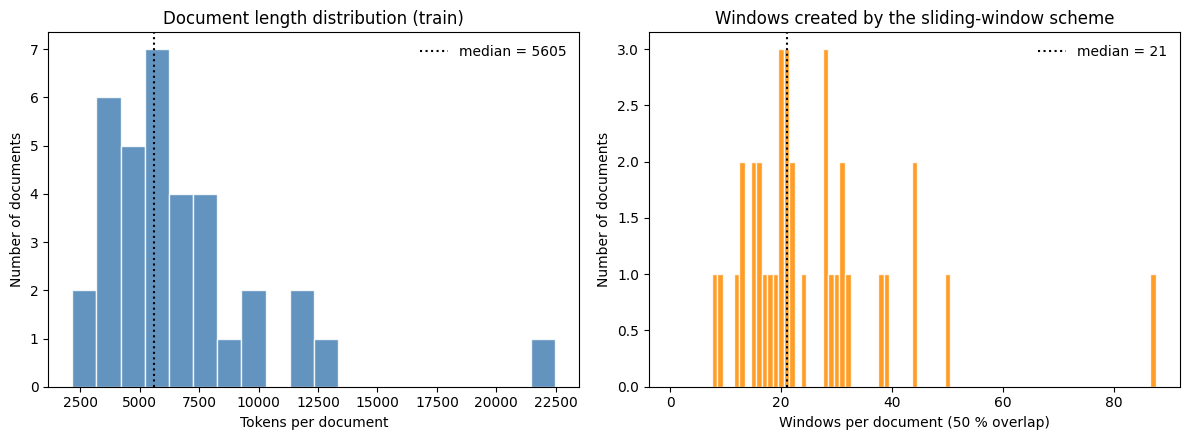

Documents longer than WINDOW_LEN=512: 35 / 35
Total training windows: 901


In [9]:
import matplotlib.pyplot as plt

train_len = np.array([len(x["ids"]) for x in train_docs.values()])
train_win = np.array([len(make_windows(n, WINDOW_LEN, WINDOW_LEN // 2)) for n in train_len])

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

# 1. Document length (tokens)
axes[0].hist(train_len, bins=20, color="steelblue", edgecolor="white", alpha=0.85)
axes[0].axvline(np.median(train_len), color="black", ls=":", lw=1.5, label=f"median = {int(np.median(train_len))}")
axes[0].set_xlabel("Tokens per document")
axes[0].set_ylabel("Number of documents")
axes[0].set_title("Document length distribution (train)")
axes[0].legend(frameon=False)

# 2. Resulting number of overlapping windows
axes[1].hist(train_win, bins=range(1, train_win.max()+2), color="darkorange", edgecolor="white", alpha=0.85, align="left")
axes[1].axvline(np.median(train_win), color="black", ls=":", lw=1.5, label=f"median = {int(np.median(train_win))}")
axes[1].set_xlabel("Windows per document (50 % overlap)")
axes[1].set_ylabel("Number of documents")
axes[1].set_title("Windows created by the sliding-window scheme")
axes[1].legend(frameon=False)

plt.tight_layout()
plt.show()

print(f"Documents longer than WINDOW_LEN={WINDOW_LEN}: {(train_len > WINDOW_LEN).sum()} / {len(train_len)}")
print(f"Total training windows: {train_win.sum()}")

## 5. Finetuning Methods

In [8]:
class LoRALinear(nn.Module):
    """y = Wx + (alpha/r) * B(A x)   (additive low-rank update)."""
    def __init__(self, base, rank, alpha, dropout=0.0):
        super().__init__()
        self.base, self.scale = base, alpha / rank
        self.A = nn.Parameter(torch.empty(rank, base.in_features))
        self.B = nn.Parameter(torch.zeros(base.out_features, rank))
        self.drop = nn.Dropout(dropout)
        nn.init.kaiming_uniform_(self.A, a=math.sqrt(5))
    def forward(self, x):
        return self.base(x) + self.scale * F.linear(F.linear(self.drop(x), self.A), self.B)

class LoRMALinear(nn.Module):
    """y = Wx + (alpha/r) * B(A(Wx))  ==  (I + s*BA) W x   (multiplicative low-rank update)."""
    def __init__(self, base, rank, alpha, dropout=0.0):
        super().__init__()
        self.base, self.scale = base, alpha / rank
        self.A = nn.Parameter(torch.empty(rank, base.out_features))
        self.B = nn.Parameter(torch.zeros(base.out_features, rank))
        nn.init.kaiming_uniform_(self.A, a=math.sqrt(5))
    def forward(self, x):
        y = self.base(x)
        return y + self.scale * F.linear(F.linear(y, self.A), self.B)

class AdaLoRALinear(nn.Module):
    """Delta W = P diag(lambda * mask) Q. Orthogonality penalty + rank pruning (see AdaLoRAController)."""
    def __init__(self, base, rank, alpha, dropout=0.0):
        super().__init__()
        self.base, self.rank, self.scale = base, rank, alpha / rank
        self.P    = nn.Parameter(torch.empty(base.out_features, rank))
        self.diag = nn.Parameter(torch.zeros(rank))
        self.Q    = nn.Parameter(torch.empty(rank, base.in_features))
        self.register_buffer("mask", torch.ones(rank))           # 0 = pruned singular value
        nn.init.orthogonal_(self.P); nn.init.orthogonal_(self.Q)
    def orth_loss(self):
        eye = torch.eye(self.rank, device=self.P.device)
        return ((self.P.T @ self.P - eye) ** 2).sum() + ((self.Q @ self.Q.T - eye) ** 2).sum()
    def forward(self, x):
        low_rank = F.linear(x, self.Q) * (self.diag * self.mask)
        return self.base(x) + self.scale * F.linear(low_rank, self.P)

class AdaLoRAController:
    """Prunes singular values by smoothed sensitivity |lambda * grad| following a cubic budget schedule."""
    def __init__(self, modules, total_steps, final_ratio, warmup_frac=0.1, freeze_frac=0.2, prune_every=20, beta=0.85):
        self.modules, self.prune_every, self.beta = modules, prune_every, beta
        self.initial_budget = sum(m.rank for m in modules)
        self.final_budget = int(self.initial_budget * final_ratio)
        self.start_step = int(total_steps * warmup_frac)
        self.end_step = int(total_steps * (1 - freeze_frac))
        self.importance = [torch.zeros_like(m.diag) for m in modules]
    def budget_at(self, step):
        if step < self.start_step: return self.initial_budget
        if step >= self.end_step:  return self.final_budget
        progress = (step - self.start_step) / (self.end_step - self.start_step)
        return int(self.final_budget + (self.initial_budget - self.final_budget) * (1 - progress) ** 3)
    @torch.no_grad()
    def update(self, step):
        """Call after backward (grads unscaled), before optimizer.step()."""
        if step >= self.end_step:
            return
        for module, imp in zip(self.modules, self.importance):
            imp.mul_(self.beta).add_((1 - self.beta) * (module.diag * module.diag.grad).abs())
        if step >= self.start_step and step % self.prune_every == 0:
            all_scores = torch.cat(self.importance)
            budget = self.budget_at(step)
            threshold = torch.topk(all_scores, budget).values[-1]
            for module, imp in zip(self.modules, self.importance):
                module.mask.copy_((imp >= threshold).float())
    def active_rank(self):
        return int(sum(m.mask.sum().item() for m in self.modules))

class AdapterBlock(nn.Module):
    """Houlsby-style bottleneck adapter applied to the output of a transformer block."""
    def __init__(self, block, d_model, bottleneck):
        super().__init__()
        self.block = block
        self.down, self.up = nn.Linear(d_model, bottleneck), nn.Linear(bottleneck, d_model)
        nn.init.zeros_(self.up.weight); nn.init.zeros_(self.up.bias)
    def forward(self, x, position_ids, attn_mask=None, kv_cache=None, use_cache=False):
        h, cache = self.block(x, position_ids, attn_mask)
        return h + self.up(F.gelu(self.down(h))), cache

PEFT_WRAPPERS = {"lora": LoRALinear, "lorma": LoRMALinear, "adalora": AdaLoRALinear}
ATTN_PROJ_NAMES = ("q_proj", "k_proj", "v_proj", "out_proj", "kv_down_proj", "k_up_proj", "v_up_proj")  # GQA and MLA names

def wrap_attention_projections(backbone, wrapper_cls, rank, alpha, dropout=0.0):
    """Wrap every attention projection that exists in this architecture (GQA / MLA / conv variants)."""
    for block in backbone.blocks:
        for name in ATTN_PROJ_NAMES:
            if hasattr(block.attn, name):
                setattr(block.attn, name, wrapper_cls(getattr(block.attn, name), rank, alpha, dropout))

def freeze(module):
    for p in module.parameters():
        p.requires_grad = False

def adapt_backbone(base_lm, exp):
    """Phase 1 decoder -> backbone prepared for `exp.method` (optionally a shallower KD student)."""
    backbone = copy.deepcopy(base_lm)
    if exp.block_stride > 1:                                         # KD student: keep every n-th block
        keep = list(range(0, len(backbone.blocks), exp.block_stride))
        backbone.blocks = nn.ModuleList([backbone.blocks[i] for i in keep])
    d_model = backbone.cfg.d_model

    if exp.method in ("full", "unfreeze"):
        pass                                                         # everything trainable ("unfreeze" schedules it per epoch)
    elif exp.method == "partial":                                    # top-n blocks + final norm
        freeze(backbone)
        for block in backbone.blocks[-exp.n_top:]:
            for p in block.parameters(): p.requires_grad = True
        for p in backbone.ln_f.parameters(): p.requires_grad = True
    elif exp.method == "bitfit":                                     # bias terms only
        for name, p in backbone.named_parameters():
            p.requires_grad = name.endswith(".bias")
        assert any(p.requires_grad for p in backbone.parameters()), f"{exp.base_model} has no bias terms for BitFit"
    elif exp.method in PEFT_WRAPPERS:
        freeze(backbone)
        wrap_attention_projections(backbone, PEFT_WRAPPERS[exp.method], exp.rank, exp.alpha, exp.lora_dropout)
    elif exp.method == "adapter":
        freeze(backbone)
        backbone.blocks = nn.ModuleList([AdapterBlock(b, d_model, exp.adapter_dim) for b in backbone.blocks])
    else:
        raise ValueError(f"unknown method: {exp.method}")
    return backbone

def count_params(model):
    total = sum(p.numel() for p in model.parameters()) / 1e6
    trainable = sum(p.numel() for p in model.parameters() if p.requires_grad) / 1e6
    return total, trainable

def apply_gradual_unfreezing(model, epoch, total_epochs):
    """Layer-unfreezing schedule: top blocks first, one more group of lower blocks every epoch."""
    blocks = model.backbone.blocks
    n_unfrozen = math.ceil(len(blocks) * (epoch + 1) / total_epochs)
    for i, block in enumerate(blocks):
        for p in block.parameters():
            p.requires_grad = i >= len(blocks) - n_unfrozen
    for p in model.backbone.ln_f.parameters(): p.requires_grad = True
    for p in model.backbone.tok_emb.parameters(): p.requires_grad = (n_unfrozen == len(blocks))

## 6. Training Utilities

In [9]:
def encode_tokens(backbone, ids, attn=None, causal=True, use_ckpt=False):
    """Phase 1 decoder over right-padded [N, L] ids -> hidden states [N, L, D].
    causal=True : the pretrained left-to-right mask (padding never influences real tokens, so no mask is needed).
    causal=False: bidirectional attention with a key-padding mask built from `attn`."""
    N, L = ids.shape
    if attn is None:
        position_ids = torch.arange(L, device=ids.device).unsqueeze(0).expand(N, L)
    else:
        position_ids = (attn.long().cumsum(-1) - 1).clamp(min=0)
    mask = None if (causal or attn is None) else attn[:, None, None, :].bool()
    x = backbone.tok_emb(ids) * backbone.emb_scale
    if backbone.use_sin:
        x = x + backbone.pos_emb[position_ids]
    for block in backbone.blocks:
        if use_ckpt and torch.is_grad_enabled():
            x = checkpoint(lambda h, blk=block: blk(h, position_ids, mask)[0], x, use_reentrant=False)
        else:
            x = block(x, position_ids, mask)[0]
    return backbone.ln_f(x)

class NERHead(nn.Module):
    """Token-classification head (BIO tags) on top of the Phase 1 backbone."""
    def __init__(self, backbone, causal=False, dropout=HEAD_DROPOUT):
        super().__init__()
        self.backbone, self.causal = backbone, causal
        self.dropout = nn.Dropout(dropout)
        self.classifier = nn.Linear(backbone.cfg.d_model, NUM_LABELS)
        nn.init.normal_(self.classifier.weight, std=0.02); nn.init.zeros_(self.classifier.bias)
    def forward(self, ids, attn):
        return self.classifier(self.dropout(encode_tokens(self.backbone, ids, attn, self.causal)))

def build_model(base_lm, exp):
    return NERHead(adapt_backbone(base_lm, exp), causal=exp.causal).to(DEVICE)

def ner_class_weights(docs, power, cap=CW_CAP):
    """Inverse-frequency weights ((count_O / count_c) ** power, clipped to [1, cap]); the O tag keeps weight 1."""
    y = np.concatenate([np.array(x["y"]) for x in docs.values()]); y = y[y >= 0]
    c = np.bincount(y, minlength=NUM_LABELS).astype(float) + 1
    w = np.clip((c[0] / c) ** power, 1.0, cap); w[0] = 1.0
    return torch.tensor(w, dtype=torch.float32, device=DEVICE)

def compute_loss(logits, labels, class_weights, loss_type):
    logits, labels = logits.float().reshape(-1, NUM_LABELS), labels.reshape(-1)
    if loss_type == "ce":                                            # no imbalance handling
        return F.cross_entropy(logits, labels, ignore_index=IGN)
    if loss_type == "weighted_ce":                                   # inverse-frequency class weights
        return F.cross_entropy(logits, labels, weight=class_weights, ignore_index=IGN)
    if loss_type == "focal":                                         # down-weights easy tokens + class weights
        keep = labels != IGN
        logits, labels = logits[keep], labels[keep]
        weighted_ce = F.cross_entropy(logits, labels, weight=class_weights, reduction="none")
        pt = torch.exp(-F.cross_entropy(logits, labels, reduction="none"))
        return (((1 - pt) ** FOCAL_GAMMA) * weighted_ce).mean()
    raise ValueError(loss_type)

def kd_loss(student_logits, teacher_logits, temperature):
    """Soft-target distillation: KL(teacher || student) at temperature T, scaled by T^2."""
    return F.kl_div(F.log_softmax(student_logits / temperature, -1), F.softmax(teacher_logits / temperature, -1),
                    reduction="batchmean") * temperature * temperature

def lr_factor(step, total_steps, warmup_frac):
    """Linear warm-up, then cosine decay (multiplier of the base learning rate)."""
    warmup = warmup_frac * total_steps
    if step < warmup:
        return (step + 1) / warmup
    return 0.5 * (1 + math.cos(math.pi * (step - warmup) / max(1, total_steps - warmup)))

@torch.no_grad()
def predict_docs(model, docs, win, decode="viterbi", bs=8):
    """Overlapping windows -> averaged log-probs per token -> BIO decoding -> character spans (start, end, label)."""
    model.eval(); out = {}
    for d, x in docs.items():
        n = len(x["ids"])
        if n == 0: out[d] = []; continue
        acc = np.zeros((n, NUM_LABELS), np.float32); cnt = np.zeros(n, np.float32); wins = make_windows(n, win, win // 2)
        for i in range(0, len(wins), bs):
            ch = wins[i:i + bs]
            ids, _, m = collate([([BOS] + x["ids"][a:b], [0] * (b - a + 1)) for a, b in ch])
            with autocast(DEVICE, dtype=torch.float16, enabled=USE_AMP_PREDICT and DEVICE == "cuda"):
                lg = model(ids.to(DEVICE), m.to(DEVICE))
            lp = lg.float().log_softmax(-1).cpu().numpy()
            for k, (a, b) in enumerate(ch): acc[a:b] += lp[k, 1:b - a + 1]; cnt[a:b] += 1
        lp = acc / np.maximum(cnt, 1)[:, None]
        keep = [i for i, (s, e) in enumerate(x["offs"]) if s < e]
        if not keep: out[d] = []; continue
        lpk = lp[keep]; offk = [x["offs"][i] for i in keep]
        out[d] = tags_to_spans(viterbi(lpk) if decode == "viterbi" else lpk.argmax(-1).tolist(), offk)
    return out

## 7. Training Loop

In [10]:
def checkpoint_path(name):
    return f"{OUT}/ckpt_{name}.pt"     # latest epoch (resume point), overwritten every epoch

def best_path(name):
    return f"{OUT}/best_{name}.pt"     # best epoch only, kept separately

def save_atomic(obj, path):
    """Write to a temp file, then rename: an interruption can never corrupt the previous file."""
    torch.save(obj, path + ".tmp")
    os.replace(path + ".tmp", path)

def get_rng_state():
    return {"python": random.getstate(), "numpy": np.random.get_state(),
            "torch": torch.get_rng_state(), "cuda": torch.cuda.get_rng_state_all()}

def set_rng_state(state):
    random.setstate(state["python"]); np.random.set_state(state["numpy"])
    torch.set_rng_state(state["torch"]); torch.cuda.set_rng_state_all(state["cuda"])

def save_best(exp, best_state, best_metric, epoch):
    save_atomic({"state": best_state, "metric": best_metric, "epoch": epoch}, best_path(exp.name))

def save_epoch_checkpoint(exp, model, snapshot_keys, optimizer, scaler, adalora_ctrl, epoch, global_step, history):
    """Everything needed to continue training from the end of `epoch` (epochs completed so far)."""
    model_state = {k: v.detach().cpu() for k, v in model.state_dict().items() if k in snapshot_keys}
    save_atomic({"config": vars(exp), "epoch": epoch, "global_step": global_step, "history": history,
                 "model": model_state, "optimizer": optimizer.state_dict(), "scaler": scaler.state_dict(),
                 "adalora_importance": None if adalora_ctrl is None else [imp.cpu() for imp in adalora_ctrl.importance],
                 "rng": get_rng_state()}, checkpoint_path(exp.name))

def resume_if_checkpointed(exp, model, optimizer, scaler, adalora_ctrl, fresh_history, worst_metric):
    """Returns (start_epoch, global_step, history, best_metric, best_state).
    Fresh start values are returned when this experiment has no checkpoint yet."""
    if not os.path.exists(checkpoint_path(exp.name)):
        return 0, 0, fresh_history, worst_metric, None

    ckpt = torch.load(checkpoint_path(exp.name), map_location="cpu", weights_only=False)
    outcome = model.load_state_dict(ckpt["model"], strict=False)
    assert not outcome.unexpected_keys, outcome.unexpected_keys
    optimizer.load_state_dict(ckpt["optimizer"])
    scaler.load_state_dict(ckpt["scaler"])
    if adalora_ctrl is not None:
        for importance, saved in zip(adalora_ctrl.importance, ckpt["adalora_importance"]):
            importance.copy_(saved)
    set_rng_state(ckpt["rng"])

    best = torch.load(best_path(exp.name), map_location="cpu", weights_only=False)
    print(f"[{exp.name}] resumed after epoch {ckpt['epoch']}/{exp.epochs} (best so far {best['metric']:.4f} at epoch {best['epoch']})")
    return ckpt["epoch"], ckpt["global_step"], ckpt["history"], best["metric"], best["state"]

In [11]:
def snapshot_names(model, exp):
    """Parameters that must be restored to recover a given epoch."""
    if exp.method == "unfreeze":
        return set(model.state_dict().keys())
    trainable = {n for n, p in model.named_parameters() if p.requires_grad}
    return trainable | {k for k in model.state_dict() if k.endswith(".mask")}

def train_model(model, exp, train_docs, val_docs, teacher=None):
    items = make_items(train_docs, exp.win)
    class_weights = ner_class_weights(train_docs, exp.cw_power)
    gold_val = {d: x["gold"] for d, x in val_docs.items()}

    # backbone (adapters / unfrozen layers) and the new head get different learning rates
    trainable = [(n, p) for n, p in model.named_parameters() if p.requires_grad]
    body_params = [p for n, p in trainable if n.startswith("backbone.")]
    head_params = [p for n, p in trainable if not n.startswith("backbone.")]
    optimizer = torch.optim.AdamW([{"params": body_params, "lr": exp.lr,      "weight_decay": WEIGHT_DECAY},
                                   {"params": head_params, "lr": exp.head_lr, "weight_decay": 0.0}])
    base_lrs = [exp.lr, exp.head_lr]

    steps_per_epoch = math.ceil(len(items) / exp.batch_size)
    total_steps = exp.epochs * steps_per_epoch
    scaler = GradScaler("cuda", enabled=USE_AMP_TRAIN and DEVICE == "cuda")

    adalora_modules = [m for m in model.modules() if isinstance(m, AdaLoRALinear)]
    adalora_ctrl = AdaLoRAController(adalora_modules, total_steps, exp.adalora_final_ratio) if adalora_modules else None

    fresh_history = {"val_f1": [], "val_P": [], "val_R": [], "loss": [], "train_sec": 0.0}
    start_epoch, global_step, history, best_f1, best_state = resume_if_checkpointed(
        exp, model, optimizer, scaler, adalora_ctrl, fresh_history, worst_metric=-1.0)

    for epoch in range(start_epoch, exp.epochs):
        if exp.method == "unfreeze":
            apply_gradual_unfreezing(model, epoch, exp.epochs)
        t0 = time.time()
        model.train(); random.shuffle(items)
        epoch_loss = 0.0

        for i in tqdm(range(0, len(items), exp.batch_size), desc=f"{exp.name} ep {epoch + 1}/{exp.epochs}", leave=False):
            lr_frac = lr_factor(global_step, total_steps, WARMUP_FRAC)
            for group, base_lr in zip(optimizer.param_groups, base_lrs):
                group["lr"] = base_lr * lr_frac

            ids, labels, mask = [t.to(DEVICE) for t in collate(items[i:i + exp.batch_size])]
            with autocast(DEVICE, dtype=torch.float16, enabled=USE_AMP_TRAIN and DEVICE == "cuda"):
                logits = model(ids, mask)
            logits = logits.float()

            loss = compute_loss(logits, labels, class_weights, exp.loss_type)
            if teacher is not None:                                  # knowledge distillation (soft targets on labelled tokens)
                with torch.no_grad(), autocast(DEVICE, dtype=torch.float16, enabled=USE_AMP_TRAIN and DEVICE == "cuda"):
                    teacher_logits = teacher(ids, mask)
                sel = labels != IGN
                loss = exp.kd_ce_weight * loss + (1.0 - exp.kd_ce_weight) * kd_loss(logits[sel], teacher_logits.float()[sel], exp.kd_temperature)
            if adalora_modules:                                      # keep P, Q near-orthogonal
                loss = loss + ADALORA_ORTH_COEF * torch.stack([m.orth_loss() for m in adalora_modules]).mean()

            optimizer.zero_grad(set_to_none=True)
            scaler.scale(loss).backward()
            scaler.unscale_(optimizer)
            grad_norm = torch.nn.utils.clip_grad_norm_([p for p in model.parameters() if p.requires_grad], GRAD_CLIP)
            if adalora_ctrl is not None and torch.isfinite(grad_norm):
                adalora_ctrl.update(global_step)
            scaler.step(optimizer); scaler.update()
            epoch_loss += loss.item(); global_step += 1

        # ── validation: model selection by strict span macro-F1 ──
        metrics = strict_prf(gold_val, predict_docs(model, val_docs, exp.win, exp.decode))
        history["val_f1"].append(metrics["F1"]); history["val_P"].append(metrics["P"]); history["val_R"].append(metrics["R"])
        history["loss"].append(epoch_loss / steps_per_epoch); history["train_sec"] += time.time() - t0
        extra = f" | active AdaLoRA rank {adalora_ctrl.active_rank()}/{adalora_ctrl.initial_budget}" if adalora_ctrl else ""
        print(f"[{exp.name}] ep {epoch + 1}/{exp.epochs} loss {history['loss'][-1]:.4f} | val strict P {metrics['P']:.3f} R {metrics['R']:.3f} F1 {metrics['F1']:.4f}{extra}")

        # ── checkpoints: best model (only when improved) first, then the resume point ──
        snapshot_keys = snapshot_names(model, exp)
        if metrics["F1"] > best_f1:
            best_f1 = metrics["F1"]
            best_state = {k: v.detach().cpu().clone() for k, v in model.state_dict().items() if k in snapshot_keys}
            save_best(exp, best_state, best_f1, epoch + 1)
        save_epoch_checkpoint(exp, model, snapshot_keys, optimizer, scaler, adalora_ctrl, epoch + 1, global_step, history)

    model.load_state_dict(best_state, strict=False)                  # restore best epoch
    history["best_f1"] = best_f1
    return history

## 8. Experiment Helper

In [14]:
@dataclass
class Experiment:
    name: str
    base_model: str               # one of PHASE1_CONFIGS
    method: str                   # full | partial | unfreeze | bitfit | lora | lorma | adalora | adapter
    epochs: int
    lr: float                     # backbone / adapter learning rate
    head_lr: float                # classifier learning rate
    batch_size: int               # windows per step
    rank: int                     # LoRA / LoRMA / AdaLoRA rank
    alpha: float
    lora_dropout: float           # dropout on the LoRA input
    n_top: int                    # blocks trained by "partial"
    adapter_dim: int
    adalora_final_ratio: float    # fraction of AdaLoRA ranks kept after pruning
    block_stride: int             # 1 = all blocks; 2 = every 2nd block (KD student)
    causal: bool                  # True = pretrained left-to-right mask, False = bidirectional
    win: int                      # tokens per window (context available to the tagger)
    loss_type: str                # ce | weighted_ce | focal
    cw_power: float               # class-weight exponent (0 = no weighting)
    decode: str                   # viterbi | greedy (decoder used for validation / submission)
    teacher_name: str             # experiment whose best weights act as the KD teacher (None = no KD)
    kd_temperature: float
    kd_ce_weight: float           # weight of the hard-label loss in the KD objective

BASE = Experiment(name="", base_model=MAIN_MODEL, method="lorma", epochs=12, lr=1e-3, head_lr=1e-3, batch_size=BATCH_SIZE,
                  rank=16, alpha=32.0, lora_dropout=0.05, n_top=4, adapter_dim=64, adalora_final_ratio=0.5, block_stride=1,
                  causal=False, win=WINDOW_LEN, loss_type="weighted_ce", cw_power=0.25, decode="viterbi",
                  teacher_name=None, kd_temperature=2.0, kd_ce_weight=0.5)

def make_exp(name, **overrides):
    exp = replace(BASE, name=name, **overrides)
    cap = RS["max_epochs"]                                           # ablation / smoke modes cap the epochs
    return exp if cap is None else replace(exp, epochs=min(exp.epochs, cap))

# ── teacher (for KD): rebuilt from its saved config + best weights, so it survives a kernel restart ──
def load_teacher(exp):
    saved = json.load(open(f"{OUT}/result_{exp.teacher_name}.json"))
    teacher_exp = Experiment(**saved["config"])
    teacher = build_model(load_phase1_model(teacher_exp.base_model), teacher_exp)
    teacher.load_state_dict(torch.load(best_path(exp.teacher_name), map_location="cpu", weights_only=False)["state"], strict=False)
    teacher.eval(); freeze(teacher)
    return teacher

# ── submission ──
def write_submission(pred, name):
    submission = {d: [[int(s), int(e), l, test_docs[d]["text"][s:e]] for s, e, l in spans] for d, spans in pred.items()}
    assert set(submission) == set(test_docs), "one prediction list per test document is required"
    json_path, zip_path = f"{OUT}/prediction_{name}.json", f"{OUT}/submission_{name}.zip"
    with open(json_path, "w", encoding="utf-8") as f:
        json.dump(submission, f, ensure_ascii=False)
    with zipfile.ZipFile(zip_path, "w", zipfile.ZIP_DEFLATED) as z:
        z.write(json_path, "prediction.json")
    print(f"  -> {zip_path}")

def run_experiment(exp, keep_model=False):
    """Build -> train -> evaluate -> write submission -> save results. A finished experiment is restored from its checkpoint."""
    result_path = f"{OUT}/result_{exp.name}.json"

    set_seed(SEED)
    base_lm = load_phase1_model(exp.base_model)
    model = build_model(base_lm, exp)
    del base_lm; gc.collect()
    total_m, trainable_m = count_params(model)
    print(f"\n=== {exp.name}: total {total_m:.1f}M | trainable {trainable_m:.2f}M ({100 * trainable_m / total_m:.1f}%)")
    teacher = load_teacher(exp).to(DEVICE) if exp.teacher_name is not None else None

    if DEVICE == "cuda": torch.cuda.reset_peak_memory_stats()
    history = train_model(model, exp, train_docs, val_docs, teacher)
    del teacher

    # validation inference (timed), then the other decoder for comparison
    t0 = time.perf_counter()
    pred = predict_docs(model, val_docs, exp.win, exp.decode)
    infer_sec = time.perf_counter() - t0
    peak_gb = torch.cuda.max_memory_allocated() / 2**30 if DEVICE == "cuda" else float("nan")
    metrics = strict_prf(gold_val, pred)
    other = "greedy" if exp.decode == "viterbi" else "viterbi"
    f1_other = strict_prf(gold_val, predict_docs(model, val_docs, exp.win, other))["F1"]

    if RS["write_test"]:
        write_submission(predict_docs(model, test_docs, exp.win, exp.decode), exp.name)

    result = {"name": exp.name, "config": vars(exp), "total_M": total_m, "trainable_M": trainable_m,
              "size_MB_fp32": total_m * 4 * 1e6 / 2**20, "P": metrics["P"], "R": metrics["R"], "F1": metrics["F1"],
              f"F1_{other}": f1_other, "per": metrics["per"], "errors": span_error_breakdown(gold_val, pred),
              "train_min": history["train_sec"] / 60, "infer_s": infer_sec, "peak_GB": peak_gb, "history": history}
    with open(result_path, "w") as f:
        json.dump(result, f, indent=2)
    print(f"### {exp.name}: val strict macro  P {metrics['P']:.4f}  R {metrics['R']:.4f}  F1 {metrics['F1']:.4f}  ({other} decode F1 {f1_other:.4f})")

    if keep_model:
        return model
    model.cpu(); del model; gc.collect(); torch.cuda.empty_cache()

## 9. Smoke Test

In [15]:
lm = load_phase1_model(MAIN_MODEL).to(DEVICE).eval()
x = torch.tensor([[BOS] + train_docs[next(iter(train_docs))]["ids"][:WINDOW_LEN]], device=DEVICE)
with torch.no_grad():
    logits = lm(x[:, :-1])
lm_loss = F.cross_entropy(logits.float().reshape(-1, logits.size(-1)), x[:, 1:].reshape(-1)).item()
print(f"Phase-1 LM loss on a legal doc: {lm_loss:.3f} (random init ~ {math.log(VOCAB_SIZE):.1f})")
del lm; gc.collect(); torch.cuda.empty_cache()

Phase-1 LM loss on a legal doc: 2.867 (random init ~ 9.9)


## 10. Run Experiment

In [ ]:
# Full fine-tuning (bidirectional): performance ceiling AND the KD teacher
run_experiment(make_exp("full_bidir", method="full", epochs=5, lr=5e-5, batch_size=4))


=== full_bidir: total 65.8M | trainable 65.77M (100.0%)


full_bidir ep 1/3:   0%|          | 0/72 [00:00<?, ?it/s]

In [ ]:
# Teacher: full_bidir. Student: same Phase 1 model keeping every 2nd block, distilled from the teacher's logits.
run_experiment(make_exp("kd_student", method="full", block_stride=2, teacher_name="full_bidir", epochs=12, lr=5e-5, batch_size=4,
                        kd_temperature=2.0, kd_ce_weight=0.5))
# Control: the same student without a teacher
run_experiment(make_exp("student_noKD", method="full", block_stride=2, epochs=12, lr=5e-5, batch_size=4))

In [ ]:
# Fine-tuning / parameter-efficient techniques on the main Phase 1 model
run_experiment(make_exp("partial_top4",  method="partial", epochs=10, lr=1e-4, n_top=4))
run_experiment(make_exp("lora_r16",      method="lora",    epochs=12, lr=1e-3, rank=16, alpha=32.0))    # the notebook I received had epochs=1 here: set it to what you trained
run_experiment(make_exp("lorma_r16",     method="lorma",   epochs=12, lr=1e-3, rank=16, alpha=32.0))
run_experiment(make_exp("adapter_64",    method="adapter", epochs=6,  lr=1e-3, adapter_dim=64))

# Additional techniques (new; the spec lists BitFit, the others complete the toolkit)
# BitFit needs bias terms: gqa-rope has biased FFNs (the SwiGLU/MoE variants only have LayerNorm biases)
run_experiment(make_exp("bitfit",           method="bitfit",  epochs=12, lr=1e-3))
run_experiment(make_exp("adalora_r16",      method="adalora", epochs=12, lr=1e-3, adalora_final_ratio=0.5))
run_experiment(make_exp("gradual_unfreeze", method="unfreeze", epochs=6, lr=5e-5, batch_size=4))

In [ ]:
# The same technique (LoRMA) on every Phase 1 architecture (lorma_r16 above already covers MAIN_MODEL)
for model_name in PHASE1_CONFIGS:
    if model_name != MAIN_MODEL:
        run_experiment(make_exp(f"lorma_{model_name}", base_model=model_name, method="lorma"))

In [ ]:
# Attention mask: pretrained causal vs bidirectional (compare with lora_r16 / full_bidir)
run_experiment(make_exp("abl_causal_lora", method="lora", causal=True, epochs=12, lr=1e-3))
run_experiment(make_exp("abl_causal_full", method="full", causal=True, epochs=10, lr=5e-5, batch_size=4))

# Context window (compare with lorma_r16, window 512)
for win in [256, 1024]:
    run_experiment(make_exp(f"abl_win_{win}", method="lorma", win=win))

# Class imbalance handling (compare with lorma_r16: weighted_ce, power 0.25)
for loss_type in ["ce", "focal"]:
    run_experiment(make_exp(f"abl_loss_{loss_type}", method="lorma", loss_type=loss_type))
run_experiment(make_exp("abl_cw_power_0.5", method="lorma", cw_power=0.5))

# Span decoding: every run also reports the other decoder's F1 (F1_greedy next to the Viterbi F1)

In [ ]:
def load_results():
    rows = []
    for file in sorted(os.listdir(OUT)):
        if file.startswith("result_") and file.endswith(".json"):
            r = json.load(open(f"{OUT}/{file}")); c = r["config"]
            rows.append({"name": r["name"], "model": c["base_model"], "method": c["method"], "win": c["win"], "causal": c["causal"],
                         "loss": c["loss_type"], "cw": c["cw_power"], "P": r["P"], "R": r["R"], "F1": r["F1"],
                         "F1_greedy": r.get("F1_greedy", float("nan")), "total_M": r["total_M"], "trainable_M": r["trainable_M"],
                         "size_MB": r["size_MB_fp32"], "train_min": r["train_min"], "infer_s": r["infer_s"], "peak_GB": r["peak_GB"]})
    return pd.DataFrame(rows).sort_values("F1", ascending=False).reset_index(drop=True)

results_df = load_results()
pd.set_option("display.width", 250, "display.max_columns", 30)
print(results_df.round(4).to_string())

In [ ]:
def error_analysis(name):
    r = json.load(open(f"{OUT}/result_{name}.json"))
    print(f"{name} | error breakdown (counts):", r["errors"])
    print("per-label strict P / R / F1 (support):")
    for label, (p, rec, f, n) in r["per"].items():
        print(f"  {label:10s} P {p:.3f} R {rec:.3f} F1 {f:.3f}  support={n}")

error_analysis(results_df.loc[0, "name"])      # best experiment on validation

In [ ]:
def write_best_per_model(df):
    """Best experiment of every Phase 1 model -> submission_best_<model>.zip (one submission per architecture)."""
    for model_name, group in df.groupby("model"):
        best = group.sort_values("F1", ascending=False).iloc[0]["name"]
        src = f"{OUT}/submission_{best}.zip"
        if os.path.exists(src):
            shutil.copy(src, f"{OUT}/submission_best_{model_name}.zip")
            print(f"{model_name:22s} <- {best:28s} val F1 {group['F1'].max():.4f}")

if RS["write_test"]:
    write_best_per_model(results_df)
    best = results_df.loc[0, "name"]                                 # overall best -> the final prediction.json / submission.zip
    shutil.copy(f"{OUT}/prediction_{best}.json", f"{OUT}/prediction.json")
    with zipfile.ZipFile(f"{OUT}/submission.zip", "w", zipfile.ZIP_DEFLATED) as z:
        z.write(f"{OUT}/prediction.json", "prediction.json")
    print("\nBEST on validation:", best, "-> wrote", f"{OUT}/submission.zip")
else:
    print(f"RUN_MODE={RUN_MODE}: no test predictions were written (analysis only)")